## Data Exploration

In [1]:
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
DB = root / 'Lectures/modeling/data/equities_top2000.duckdb'

con = duckdb.connect(str(DB), read_only=True)
q = lambda sql: con.execute(sql).fetchdf()

In [3]:
display(q("SELECT table_name FROM information_schema.tables ORDER BY 1"))

pd.set_option("display.max_columns", None)  
tables = q("SELECT table_name FROM information_schema.tables ORDER BY 1").table_name.tolist()

for table in tables:
    n_rows = q(f'SELECT COUNT(*) AS n FROM "{table}"').n.iloc[0]
    print(f"\n{'=' * 70}\n{table}  ({n_rows:,} rows)\n{'=' * 70}")
    display(q(f'DESCRIBE "{table}"')[["column_name", "column_type", "null"]]) 
    display(q(f'SELECT * FROM "{table}" LIMIT 3'))  

,table_name
0,benchmark
1,calendar
2,dataset_metadata
3,dividends
4,fundamentals
5,prices
6,universe
7,universe_candidates
8,universe_membership
9,universe_rebalances



benchmark  (6,726 rows)


,column_name,column_type,null
0,symbol,VARCHAR,YES
1,date,DATE,YES
2,close,DOUBLE,YES
3,adj_close,DOUBLE,YES
4,source,VARCHAR,YES


,symbol,date,close,adj_close,source
0,^SP500TR,2000-01-03,2002.11,2002.11,fmp
1,^SP500TR,2000-01-04,1925.41,1925.41,fmp
2,^SP500TR,2000-01-05,1929.28,1929.28,fmp



calendar  (6,726 rows)


,column_name,column_type,null
0,date,DATE,YES


... (21 outputs left out)

,quarter_start,quarter_end,selection_date,effective_start,symbol,selection_close,shares_fiscal_date,shares_filing_date,shares_available_date,selection_shares,market_cap_proxy,universe_rank
0,2000-01-01,2000-03-31,1999-12-31,2000-01-03,SEEL,71243520.00,1999-09-30,1999-11-12,1999-11-13,1.000000e+04,7.124352e+11,1
1,2000-01-01,2000-03-31,1999-12-31,2000-01-03,MSFT,58.38,1999-09-30,1999-11-05,1999-11-06,1.105400e+10,6.453325e+11,2
2,2000-01-01,2000-03-31,1999-12-31,2000-01-03,CSCO,53.56,1999-10-30,1999-12-14,1999-12-15,7.288000e+09,3.903453e+11,3



universe_rebalances  (107 rows)


,column_name,column_type,null
0,quarter_start,DATE,YES
1,quarter_end,DATE,YES
2,selection_date,DATE,YES
3,effective_start,DATE,YES
4,positive_quote_candidates,BIGINT,YES
5,rankable_candidates,BIGINT,YES
6,selected_count,BIGINT,YES
7,shortfall,BIGINT,YES
8,selected_currently_inactive,BIGINT,YES
9,delivered_members,BIGINT,YES


,quarter_start,quarter_end,selection_date,effective_start,positive_quote_candidates,rankable_candidates,selected_count,shortfall,selected_currently_inactive,delivered_members
0,2000-01-01,2000-03-31,1999-12-31,2000-01-03,1383,1206,1206,794,204,1206
1,2000-04-01,2000-06-30,2000-03-31,2000-04-03,1405,1220,1220,780,209,1220
2,2000-07-01,2000-09-30,2000-06-30,2000-07-03,1422,1248,1248,752,217,1248


,quarter_start,selected_count,shortfall
40,2010-01-01,1893,107
41,2010-04-01,1903,97
42,2010-07-01,1931,69
43,2010-10-01,1946,54
44,2011-01-01,1963,37
45,2011-04-01,1983,17


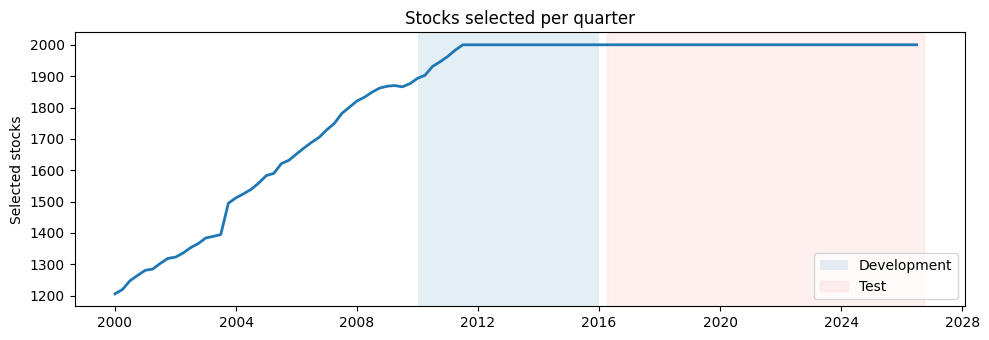

In [4]:
reb = q("SELECT quarter_start, selected_count, shortfall FROM universe_rebalances ORDER BY 1")
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(reb.quarter_start, reb.selected_count, lw=2)
ax.axvspan(pd.Timestamp("2010-01-01"), pd.Timestamp("2016-01-01"), alpha=0.12, label="Development")
ax.axvspan(pd.Timestamp("2016-04-01"), pd.Timestamp("2026-09-30"), alpha=0.06, color="red", label="Test")
ax.set(title="Stocks selected per quarter", ylabel="Selected stocks")
ax.legend(loc="lower right")
plt.tight_layout()
display(reb.loc[(reb.shortfall > 0) & (reb.quarter_start >= pd.Timestamp("2010-01-01"))])

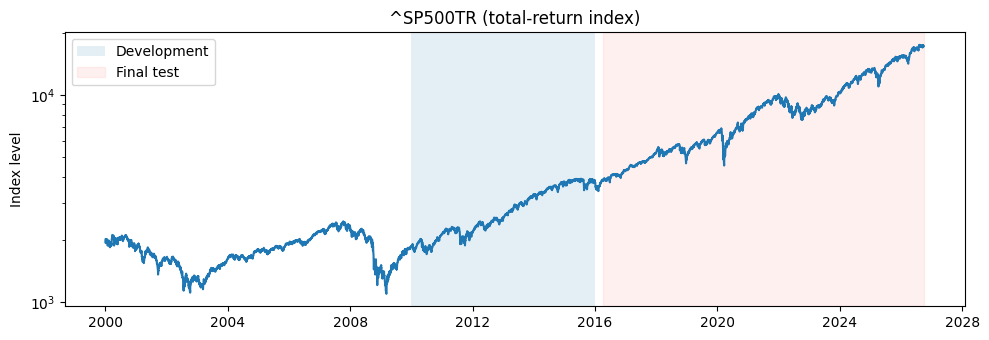

In [5]:
bench = q("SELECT date, adj_close FROM benchmark ORDER BY date")
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(bench.date, bench.adj_close, lw=1.5)
ax.axvspan(pd.Timestamp("2010-01-01"), pd.Timestamp("2016-01-01"), alpha=0.12, label="Development")
ax.axvspan(pd.Timestamp("2016-04-01"), pd.Timestamp("2026-09-30"), alpha=0.06, color="red", label="Final test")
ax.set(title="^SP500TR (total-return index)", ylabel="Index level", yscale="log")
ax.legend(loc="upper left")
plt.tight_layout()


,missing_filing,filing_on_or_before_fiscal_end
0,0,23664


count    260534.000000
mean         50.751672
std         201.833521
min           1.000000
25%          35.000000
50%          39.000000
75%          47.000000
max        8804.000000
Name: lag_days, dtype: float64

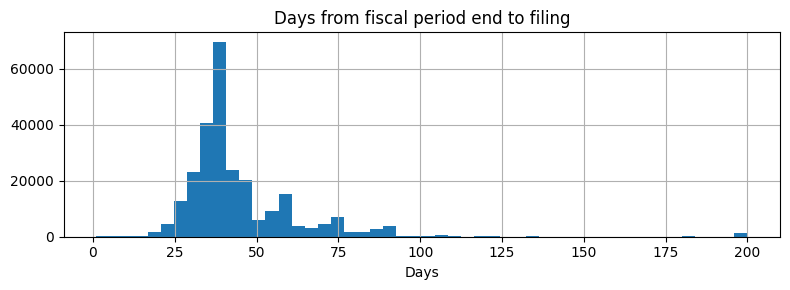

In [6]:
lags = q("""
    SELECT datediff('day', fiscal_date, filing_date) AS lag_days
    FROM fundamentals WHERE filing_date > fiscal_date
""")
display(q("""
    SELECT COUNT(*) FILTER (WHERE filing_date IS NULL)        AS missing_filing,
           COUNT(*) FILTER (WHERE filing_date <= fiscal_date) AS filing_on_or_before_fiscal_end
    FROM fundamentals
"""))
display(lags.lag_days.describe())
lags.lag_days.clip(upper=200).hist(bins=50, figsize=(8, 3))
plt.title("Days from fiscal period end to filing")
plt.xlabel("Days"); plt.tight_layout()


## Test Features

In [7]:
%load_ext autoreload
%autoreload 2
import pandas as pd
from features import technical_features, load_calendar, TEST_DB
from course_data import load_data

In [8]:
prices, fundamentals, universe, benchmark = load_data(TEST_DB, end="2015-12-31", symbols=["AAPL"])
calendar = pd.DatetimeIndex(benchmark.date)
px = prices.set_index('date').adj_close.reindex(calendar)

In [9]:
tech = technical_features(px)

In [10]:
tech.head(25)

,rsi_21,dma_20,dma_50,dma_100
date,,,,
2008-01-02,NaN,NaN,NaN,NaN
2008-01-03,NaN,NaN,NaN,NaN
2008-01-04,NaN,NaN,NaN,NaN
2008-01-07,NaN,NaN,NaN,NaN
2008-01-08,NaN,NaN,NaN,NaN
2008-01-09,NaN,NaN,NaN,NaN
2008-01-10,NaN,NaN,NaN,NaN
2008-01-11,NaN,NaN,NaN,NaN
2008-01-14,NaN,NaN,NaN,NaN
